<a href="https://colab.research.google.com/github/diogenesjusto/FIAP/blob/master/MBAIA/18DTSR/18DTSR_Aula2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Parte 1: transf. Log e Transf. Polinomial

In [138]:
# Bibliotecas
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.preprocessing import PolynomialFeatures

In [139]:
df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/master/dados/mtcars.csv")

# Transformação de Variáveis (feat. engineering)

In [140]:
# Hipótese 1: wt tem um "crescimento exponencial" em relação a MPG, ou seja, não é "perfeitamente linear"
df['wt_log'] = np.log(df['wt'])


In [141]:
# Hipótese 2: vamos tentar modelar o crescimento de Wt como uma curva quadrática
# Fc. de transf. polinomial
poly = PolynomialFeatures(degree=11)

# Análise de Correlação

In [142]:
df[['mpg', 'wt', 'wt_log']].corr()

,mpg,wt,wt_log
mpg,1.000000,-0.867659,-0.900081
wt,-0.867659,1.000000,0.978822
wt_log,-0.900081,0.978822,1.000000


<Axes: xlabel='wt', ylabel='mpg'>

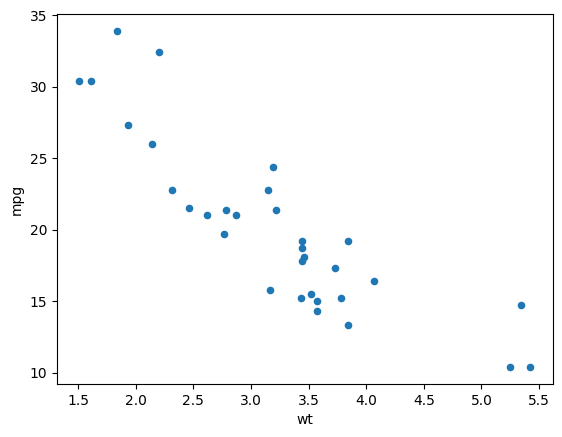

In [143]:
# Análise de correlação: gráfico de dispersão
df.plot.scatter(x="wt", y="mpg")

<Axes: xlabel='wt_log', ylabel='mpg'>

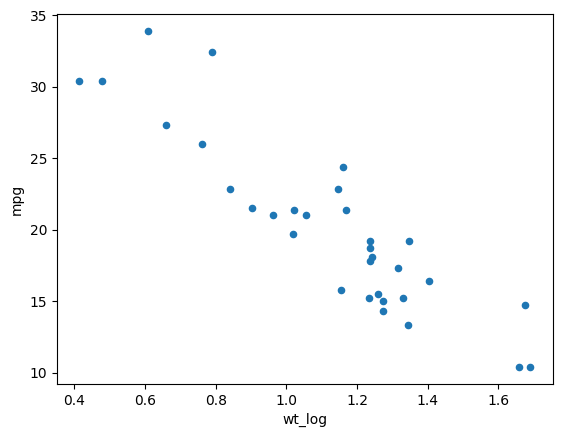

In [144]:
# Análise de correlação: gráfico de dispersão
df.plot.scatter(x="wt_log", y="mpg")

In [145]:
# Separação de dados em treino e teste
# Utilização da transf. Log
# x_treino, x_teste, y_treino, y_teste = train_test_split(df[['wt_log']], df['mpg'], test_size=0.3, random_state=1)
# Utilização da Transf.Polinomial
x_treino, x_teste, y_treino, y_teste = train_test_split(df[['wt']], df['mpg'], test_size=0.3, random_state=1)


In [146]:
x_treino

,wt
24,3.845
10,3.440
20,2.465
26,2.140
4,3.440
2,2.320
25,1.935
6,3.570
13,3.780
7,3.190


In [147]:
# Aplicando a transformação polinomial
x_treino = poly.fit_transform(x_treino)
x_teste = poly.fit_transform(x_teste)

In [148]:
# Ou seja, na transf. Polinomial, são criadas novas features que nada mais são que x^2, e assim por diante
x_treino

array([[1.00000000e+00, 3.84500000e+00, 1.47840250e+01, 5.68445761e+01,
        2.18567395e+02, 8.40391635e+02, 3.23130583e+03, 1.24243709e+04,
        4.77717062e+04, 1.83682211e+05, 7.06258099e+05, 2.71556239e+06],
       [1.00000000e+00, 3.44000000e+00, 1.18336000e+01, 4.07075840e+01,
        1.40034089e+02, 4.81717266e+02, 1.65710740e+03, 5.70044944e+03,
        1.96095461e+04, 6.74568385e+04, 2.32051524e+05, 7.98257244e+05],
       [1.00000000e+00, 2.46500000e+00, 6.07622500e+00, 1.49778946e+01,
        3.69205103e+01, 9.10090578e+01, 2.24337327e+02, 5.52991512e+02,
        1.36312408e+03, 3.36010085e+03, 8.28264860e+03, 2.04167288e+04],
       [1.00000000e+00, 2.14000000e+00, 4.57960000e+00, 9.80034400e+00,
        2.09727362e+01, 4.48816554e+01, 9.60467425e+01, 2.05540029e+02,
        4.39855662e+02, 9.41291117e+02, 2.01436299e+03, 4.31073680e+03],
       [1.00000000e+00, 3.44000000e+00, 1.18336000e+01, 4.07075840e+01,
        1.40034089e+02, 4.81717266e+02, 1.65710740e+03, 5.70

In [149]:
# Regressão Linear
mod = LinearRegression()
mod.fit(x_treino, y_treino)

LinearRegression()

In [150]:
# Coef. angular da "reta"
mod.coef_

array([ 0.00000000e+00,  1.50437766e+06, -8.96346246e+05, -6.67534152e+05,
        1.42107570e+06, -1.07278007e+06,  4.74711540e+05, -1.35558882e+05,
        2.53836315e+04, -3.02091189e+03,  2.07677579e+02, -6.28589869e+00])

In [151]:
# Coef. de Intercepto ou Linear
mod.intercept_

np.float64(-672609.4183150673)

In [152]:
# R2
print(mod.score(x_treino, y_treino))

0.9689782480492268


In [153]:
# Previsão
y_prev = mod.predict(x_teste)
y_prev

array([-911.26302317,   23.38684295,   18.63848673, -357.12419395,
         18.84108912,   24.42530885,   16.25281368,   23.62100349,
          3.97097424, -362.2576362 ])

In [154]:
# Como calcular uma previsão "na mão"
# mpg = a*wt + b
# mpg = (-3.9)*wt + 32.5.  |. a e b, ou seja, -3.9 e 32.5 vieram de um cálculo utilizando os dados de treino
# Para "prever", precisamos "aplicar a fórmula acima" sobre os dados de teste
# O primeiro valor de x_teste é 1.5
# Portanto, mpg previsto para o 1.o veículo da base teste, é mpg_prev = (-3.9)*(1.5) + 32.5
(-3.9)*(1.5) + 32.5

26.65

In [155]:
# Cálculo do Erro de Previsão
mse = mean_squared_error(y_teste, y_prev)
mse

117684.55154264723

## Parte 2 - Transf. Log para Redistribuição de dados

In [157]:
df_Redist = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/RFM.csv")
df_Redist

,PARTNER_ID,CUSTOMER_ID,CodFamilia,PRODUCT_ID,STORE_ID,AMOUNT,DATE,DISCOUNT_AMOUNT,DISPLAY_FLAG,FEATURE_FLAG,GROSS_PROFIT_AMOUNT,POINTS_BONUS_AMOUNT,QUANTITY,CATEGORY_1,CATEGORY_2,CATEGORY_3,CATEGORY_4,NAME
0,1160653,95595791691,138104,196282,409,8.98,2020-01-01 00:14:41 UTC,0.0,0,0,3.875962,40,2.0,MERCEARIA,BOMBONIERE SECAO,BOMBONS-CHOCOLATES,CHOC BARRA-TABLETE,CHOC GAROTO 90G-TA CAST CAJU
1,1160653,8814812624,97760,136956,62,0.00,2020-01-01 00:10:16 UTC,0.0,0,0,-60.099320,120,4.0,MERCEARIA,BEBIDAS,VINHOS,VIN CHILENO,VIN CHIL ANTAKARI RSV 750ML CHARD
2,1160653,38552620634,247,329,408,9.98,2020-01-01 00:08:29 UTC,0.0,0,0,2.965819,20,1.0,MERCEARIA,MATINAIS SECAO,CAFES,CAFE CAPPUCINO-COM LEITE,CAPPUCCINO 3CORACOES CLAS 200G-PT
3,1160653,11561694614,77004,104089,405,7.99,2020-01-01 00:06:10 UTC,0.0,0,0,1.807759,20,1.0,MERCEARIA,CONSERVAS-CONDIMENTOS,CONDIMENTOS-TEMPEROS,CATCHUP FR ATE 500G,KETCHUP HEINZ 397G-PET TRAD
4,1160653,1216506698,138045,196180,62,11.96,2020-01-01 00:05:30 UTC,0.0,0,0,3.739260,30,2.0,PERECIVEIS,P.A.S.,VEGETAIS CONG,LEGUME CONG,ANEIS CEBOLA GOLDEN FOODS 350G-PC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92289,1160653,10264569679,113545,160178,417,2.15,2019-11-08 10:29:32 UTC,0.0,0,0,0.881706,0,1.0,MERCEARIA,BISCOITOS SECAO,BISCOITOS,BISC ESPECIAL-TORRADA,COOKIES TODDY 60G-PC BAUN/GOTAS CHOC
92290,1160653,74199480625,129263,194991,405,2.99,2019-11-08 10:29:22 UTC,0.0,0,0,1.094917,0,1.0,HIGIENE PESSOAL E BELEZA,CUIDADO CORPORAL,SABONETE BARRA GRUPO,SAB BARRA GLICERINADO,SAB PALMOLIVE N-SECRETA 90G PITAYA
92291,1160653,60400722615,113545,185621,415,4.30,2019-11-08 10:27:06 UTC,0.0,0,0,1.767366,0,2.0,MERCEARIA,BISCOITOS SECAO,BISCOITOS,BISC ESPECIAL-TORRADA,COOKIES TODDY 60G-PC MALHADO
92292,1160653,3623837660,126862,193506,65,6.29,2019-11-08 10:16:58 UTC,0.0,0,0,2.612831,0,1.0,PERECIVEIS,P.A.S.,LEITES-CREMES,ACHOC-LEITE AROMAT ATE 1L,BEB LAC NESTLE NESFIT 260ML AVEIA/CACAU


In [160]:
# Vamos transformar nossos dados para uma análise de RFM / RFV
# Inicialmente vamos criar a variável V (somatório total gasto em nossas lojas)
# e adicionalmente a coluna count inclui a variável F (frequência, ou seja, quantidade de transações)
dfAgg = df_Redist.groupby(by=['CUSTOMER_ID'])['AMOUNT'].agg(['sum', 'count'])
dfAgg

,sum,count
CUSTOMER_ID,,
191,17.82,1
1202782,13.80,1
1209604,38.79,1
1480677,8.98,1
1593609,3.99,1
...,...,...
6298976531803343,12.90,1
6298976531895851,89.90,1
6298976532232294,51.78,3


<Axes: xlabel='count', ylabel='sum'>

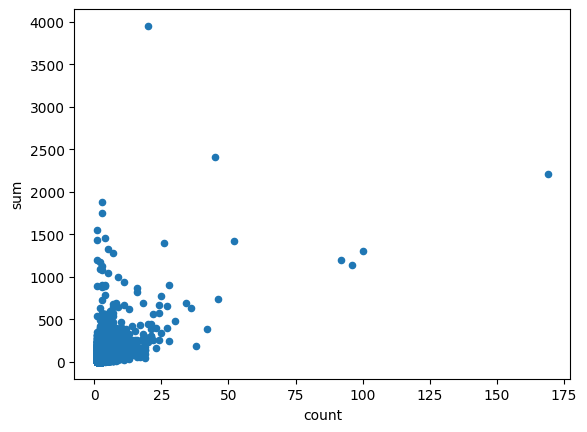

In [161]:
# Análise de distribuição de F e V
dfAgg.plot.scatter(x='count', y='sum')

array([[<Axes: title={'center': 'sum'}>]], dtype=object)

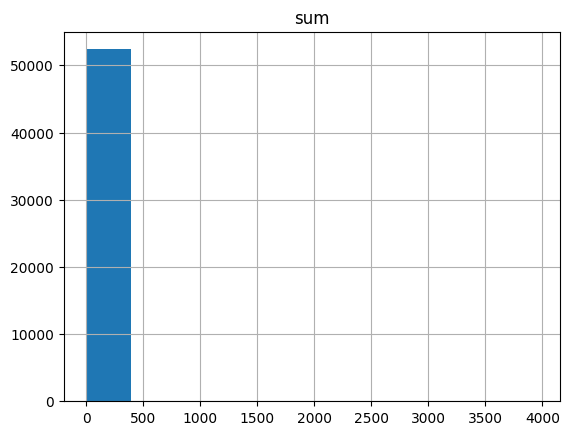

In [162]:
# Análise de distribuição univariada
dfAgg.hist('sum')

array([[<Axes: title={'center': 'count'}>]], dtype=object)

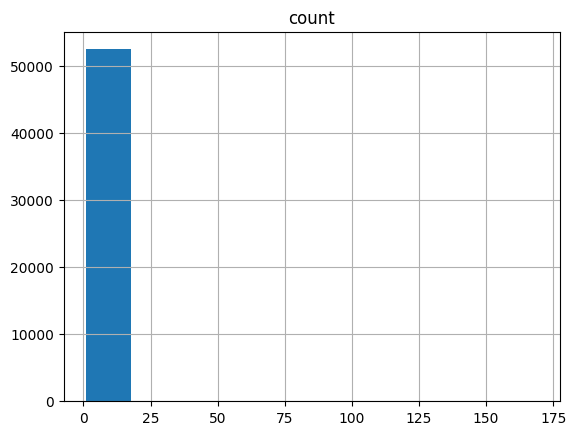

In [163]:
dfAgg.hist('count')

In [168]:
# Vamos redistribuir nossos dados para a "cauda" ganhar mais "relevância"
F = dfAgg['count'].values
V = dfAgg['sum'].values

# Para isto, vamos aplicar o log (valores iguais a zero foram aproximados a muito próximo a zero, para conseguirmos calcular o log)
V[V==0]=0.0001

F_log = np.log(F)
V_log = np.log(V)

dfAgg['count_log'] = F_log
dfAgg['sum_log'] = V_log

dfAgg


,sum,count,count_log,sum_log
CUSTOMER_ID,,,,
191,17.82,1,0.000000,2.880321
1202782,13.80,1,0.000000,2.624669
1209604,38.79,1,0.000000,3.658162
1480677,8.98,1,0.000000,2.195000
1593609,3.99,1,0.000000,1.383791
...,...,...,...,...
6298976531803343,12.90,1,0.000000,2.557227
6298976531895851,89.90,1,0.000000,4.498698
6298976532232294,51.78,3,1.098612,3.947004


In [166]:
V[V==0]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

array([[<Axes: title={'center': 'count_log'}>]], dtype=object)

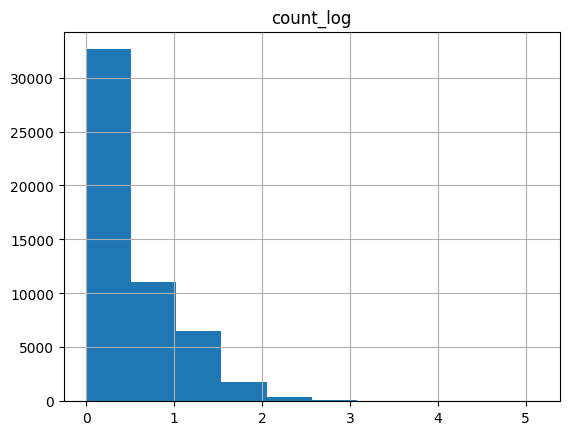

In [170]:
# Análise da distribuição de dados das variáveis após a transformação
dfAgg.hist('count_log') #Frequencia

array([[<Axes: title={'center': 'sum_log'}>]], dtype=object)

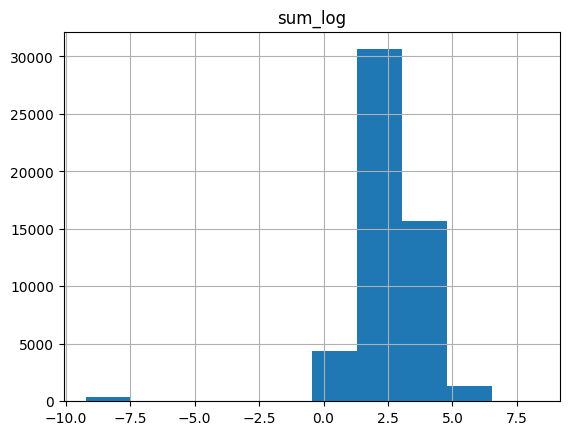

In [171]:
dfAgg.hist('sum_log') #Valor